In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [7]:
print(df.dtypes)

Дата            object
Склад            int64
Контрагент      object
Номенклатура    object
Количество       int64
dtype: object


Сразу переведем столбец "Дата" в правильный формат

In [8]:
df['Дата'] = pd.to_datetime(df['Дата'])

In [9]:
print(df.dtypes)

Дата            datetime64[ns]
Склад                    int64
Контрагент              object
Номенклатура            object
Количество               int64
dtype: object


Сгруппируйте данные по дате, посчитайте количество продаж

In [13]:
grouped_df = df.groupby('Дата')['Номенклатура'].count().reset_index(name='Количество продаж')

Вывести несколько первых строк сгруппированных данных

In [15]:
print(grouped_df)

          Дата  Количество продаж
0   2018-01-04               1840
1   2018-01-05               1301
2   2018-01-06               1306
3   2018-01-07               1322
4   2018-01-09               1719
..         ...                ...
200 2018-08-26               1462
201 2018-08-28               1731
202 2018-08-29               1497
203 2018-08-30               1445
204 2018-08-31               1366

[205 rows x 2 columns]


Нарисуйте график продаж у `grouped_df`

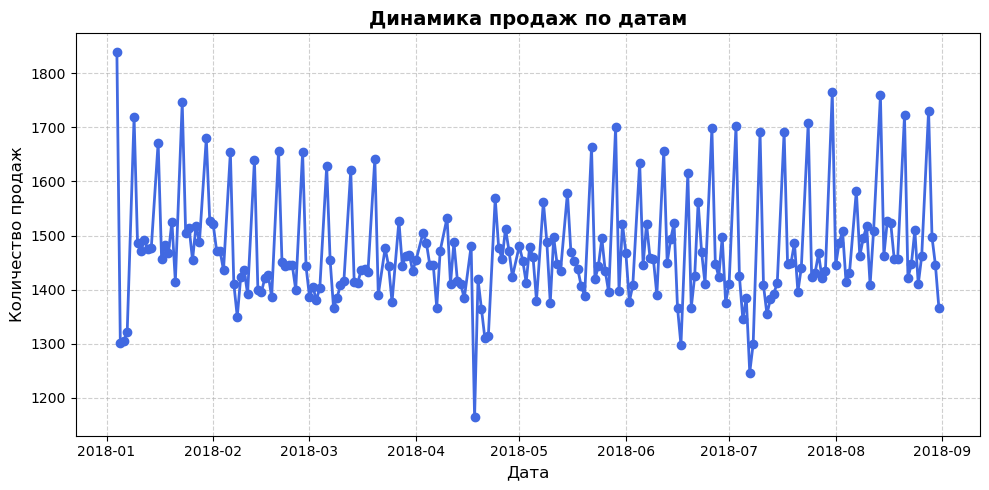

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(grouped_df['Дата'], grouped_df['Количество продаж'], marker='o', color='royalblue', linewidth=2)

plt.title('Динамика продаж по датам', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество продаж', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:
График имеет ярко выраженную пилообразную структуру : регулярные и резкие спады и подъемыпродаж. Зафиксирован абсолютный максимум продаж 1850 единиц, 
так же крупные всплески наблюдались в феврале, августе, сентябре. На графике два аномально низких значения, в мае и в июле. 
Общая тенденция количества продаж остается стабильной.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [19]:
max_row = df.loc[[df['Количество'].idxmax()]]
print(max_row)

             Дата  Склад   Контрагент Номенклатура  Количество
218822 2018-06-28      1  address_208    product_0         200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [20]:

summer_wednesdays = df[(df['Склад'] == 3) & (df['Дата'].dt.month.isin([6, 7, 8])) & (df['Дата'].dt.weekday == 2)]

top_product = summer_wednesdays.groupby('Номенклатура')['Количество'].sum().idxmax()

print(f"Топовый товар: {top_product}")

Топовый товар: product_1


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

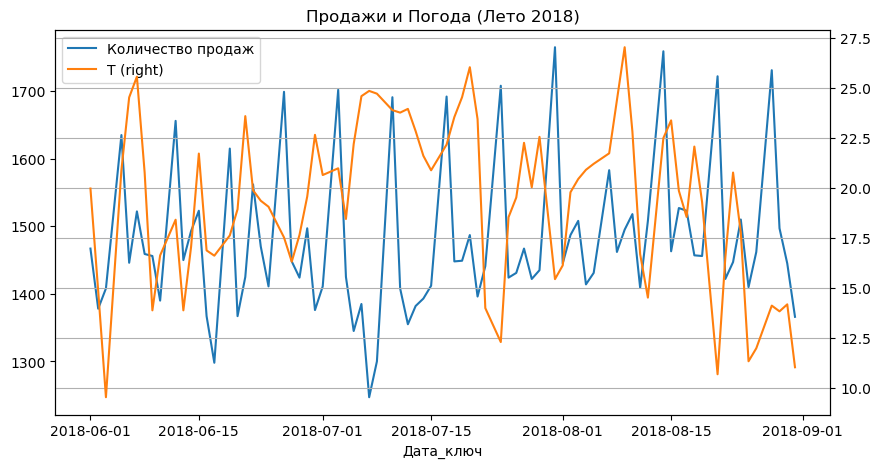

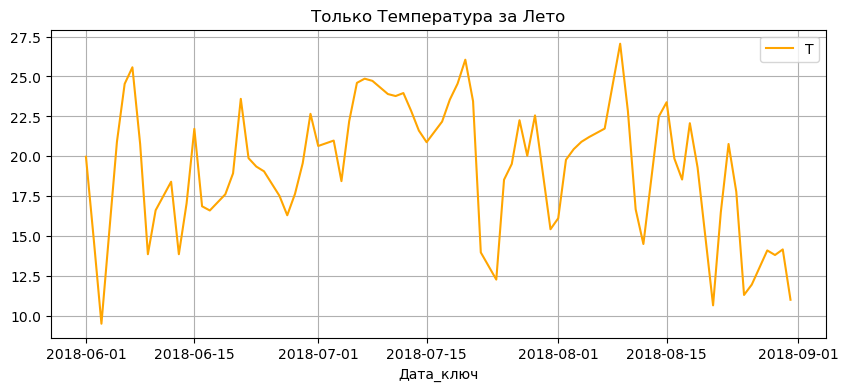

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

Weather = pd.read_csv('Weather.csv', sep=None, engine='python', skiprows=6, encoding='utf-8').iloc[::-1]

Weather = Weather.reset_index()

weather_clean = pd.DataFrame({
    'Дата_время': Weather.iloc[:, 0],
    'T': pd.to_numeric(Weather.iloc[:, 1], errors='coerce') 
})

weather_clean['Дата_ключ'] = pd.to_datetime(weather_clean['Дата_время'], format='%d.%m.%Y %H:%M', errors='coerce').dt.date

daily_weather = weather_clean.groupby('Дата_ключ')['T'].mean().reset_index()

grouped_df['Дата_ключ'] = pd.to_datetime(grouped_df['Дата']).dt.date


merged_df = pd.merge(grouped_df, daily_weather, on='Дата_ключ').sort_values('Дата_ключ')
merged_df = merged_df.set_index('Дата_ключ')

merged_df.plot(y=['Количество продаж', 'T'], secondary_y='T', figsize=(10, 5), grid=True, title='Продажи и Погода (Лето 2018)')
plt.show()

merged_df.plot(y='T', color='orange', figsize=(10, 4), grid=True, title='Только Температура за Лето')
plt.show()